# Machine Learning Assignment 2
## Classification Model Comparison

**Student:** Amit Kumar Mohanty 
**Course:** M.Tech (AIML) - Artificial Intelligence & Machine Learning  
**BITS ID:** 2026aj05290
**Date:** November 2026

---

## Objective
Implement and compare 5 classification algorithms on the Adult Income dataset using proper ML pipelines, evaluate with 6 metrics, and deploy via Streamlit.

## 1. Import Libraries

In [1]:
# Data handling
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Sklearn imports
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

# Metrics
from sklearn.metrics import (
    accuracy_score, roc_auc_score, precision_score,
    recall_score, f1_score, matthews_corrcoef,
    confusion_matrix, classification_report
)

# Model persistence
import joblib
import os

# Settings
import warnings
warnings.filterwarnings('ignore')
plt.style.use('ggplot')

print("All libraries imported successfully!")

All libraries imported successfully!


## 2. Load and Explore Dataset

### Dataset Information
- **Name:** Adult Income Dataset (Census Income)
- **Source:** UCI ML Repository via OpenML/sklearn
- **Task:** Predict if income exceeds $50K/year
- **Type:** Binary Classification
- **Samples:** 48,842
- **Features:** 14 (mix of numerical and categorical)

In [2]:
# Load dataset
print("Loading Adult Income dataset...")
from sklearn.datasets import fetch_openml

try:
    # Try loading from OpenML
    data = fetch_openml('adult', version=2, as_frame=True, parser='auto')
    df = data.frame.copy()
    
    # Find target column
    if 'class' in df.columns:
        target_col = 'class'
    elif 'income' in df.columns:
        target_col = 'income'
    else:
        target_col = df.columns[-1]
    
    print(f"Target column: {target_col}")
    
except Exception as e:
    print(f"OpenML failed: {e}")
    print("Loading from UCI repository directly...")
    
    url = "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data"
    column_names = ['age', 'workclass', 'fnlwgt', 'education', 'education-num',
                   'marital-status', 'occupation', 'relationship', 'race', 'sex',
                   'capital-gain', 'capital-loss', 'hours-per-week', 'native-country', 'income']
    
    df = pd.read_csv(url, names=column_names, na_values=' ?', skipinitialspace=True)
    target_col = 'income'

print(f"\nDataset loaded successfully!")
print(f"Shape: {df.shape}")

Loading Adult Income dataset...
Target column: class

Dataset loaded successfully!
Shape: (48842, 15)


In [3]:
# Display first few rows
print("First 5 rows of the dataset:")
df.head()

First 5 rows of the dataset:


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,class
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K
4,18,NaN,103497,Some-college,10,Never-married,NaN,Own-child,White,Female,0,0,30,United-States,<=50K


## 3. Data Understanding

In [4]:
# Basic info
print("Dataset Information:")
print("="*50)
df.info()

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype   
---  ------          --------------  -----   
 0   age             48842 non-null  int64   
 1   workclass       46043 non-null  category
 2   fnlwgt          48842 non-null  int64   
 3   education       48842 non-null  category
 4   education-num   48842 non-null  int64   
 5   marital-status  48842 non-null  category
 6   occupation      46033 non-null  category
 7   relationship    48842 non-null  category
 8   race            48842 non-null  category
 9   sex             48842 non-null  category
 10  capital-gain    48842 non-null  int64   
 11  capital-loss    48842 non-null  int64   
 12  hours-per-week  48842 non-null  int64   
 13  native-country  47985 non-null  category
 14  class           48842 non-null  category
dtypes: category(9), int64(6)
memory usage: 2.7 MB


In [5]:
# Check missing values
print("\nMissing Values:")
print("="*50)
missing = df.isnull().sum()
if missing.sum() > 0:
    print(missing[missing > 0])
else:
    print("No missing values found!")


Missing Values:
workclass         2799
occupation        2809
native-country     857
dtype: int64


In [6]:
# Check duplicates
print("\nDuplicate rows:")
print(f"Count: {df.duplicated().sum()}")


Duplicate rows:
Count: 52


In [7]:
# Target distribution
print("\nTarget Variable Distribution:")
print("="*50)
print(df[target_col].value_counts())
print("\nPercentages:")
print(df[target_col].value_counts(normalize=True) * 100)


Target Variable Distribution:
class
<=50K    37155
>50K     11687
Name: count, dtype: int64

Percentages:
class
<=50K    76.071823
>50K     23.928177
Name: proportion, dtype: float64


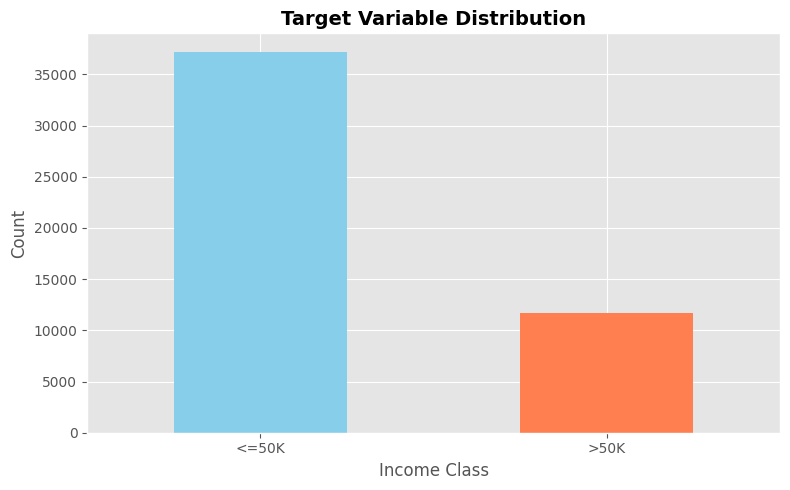


Observation: Dataset is imbalanced with more people earning ≤50K


In [8]:
# Visualize target distribution
plt.figure(figsize=(8, 5))
df[target_col].value_counts().plot(kind='bar', color=['skyblue', 'coral'])
plt.title('Target Variable Distribution', fontsize=14, fontweight='bold')
plt.xlabel('Income Class')
plt.ylabel('Count')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print("\nObservation: Dataset is imbalanced with more people earning ≤50K")

In [9]:
# Separate categorical and numerical columns
categorical_cols = df.select_dtypes(include=['object', 'category']).columns.tolist()
categorical_cols = [col for col in categorical_cols if col != target_col]

numerical_cols = df.select_dtypes(include=['int64', 'float64']).columns.tolist()

print(f"\nCategorical columns ({len(categorical_cols)}): {categorical_cols}")
print(f"\nNumerical columns ({len(numerical_cols)}): {numerical_cols}")


Categorical columns (8): ['workclass', 'education', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'native-country']

Numerical columns (6): ['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']


## 4. Data Preprocessing

Following best practices:
- Split data FIRST to avoid data leakage
- Use Pipeline to keep preprocessing and model together
- Use ColumnTransformer for different column types

In [10]:
# Prepare features and target
print("Preparing features and target...")

# Create binary target
unique_vals = sorted(df[target_col].unique())
print(f"Target values: {unique_vals}")

# Map to binary (0 and 1)
target_mapping = {unique_vals[0]: 0, unique_vals[1]: 1}
print(f"Mapping: {target_mapping}")

X = df.drop(columns=[target_col])
y = df[target_col].map(target_mapping)

print(f"\nFeatures shape: {X.shape}")
print(f"Target shape: {y.shape}")
print(f"Target distribution: {y.value_counts().to_dict()}")

Preparing features and target...
Target values: ['<=50K', '>50K']
Mapping: {'<=50K': 0, '>50K': 1}

Features shape: (48842, 14)
Target shape: (48842,)
Target distribution: {0: 37155, 1: 11687}


In [11]:
# Split into train and test sets
print("Splitting data...")

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y  # Maintain class distribution
)

print(f"Train set: {X_train.shape}")
print(f"Test set: {X_test.shape}")
print(f"\nTrain target distribution: {y_train.value_counts().to_dict()}")
print(f"Test target distribution: {y_test.value_counts().to_dict()}")

Splitting data...
Train set: (39073, 14)
Test set: (9769, 14)

Train target distribution: {0: 29724, 1: 9349}
Test target distribution: {0: 7431, 1: 2338}


In [12]:
# Handle categorical columns properly
print("Processing categorical features...")

# Convert object types to category and get codes
X_train_processed = X_train.copy()
X_test_processed = X_test.copy()

for col in categorical_cols:
    if X_train_processed[col].dtype == 'object':
        X_train_processed[col] = X_train_processed[col].astype('category').cat.codes
        X_test_processed[col] = X_test_processed[col].astype('category').cat.codes
    else:
        X_train_processed[col] = X_train_processed[col].cat.codes
        X_test_processed[col] = X_test_processed[col].cat.codes

# Replace -1 (missing codes) with mode
for col in X_train_processed.columns:
    if (X_train_processed[col] == -1).any():
        mode_val = X_train_processed[X_train_processed[col] != -1][col].mode()
        if len(mode_val) > 0:
            X_train_processed[col] = X_train_processed[col].replace(-1, mode_val[0])
            X_test_processed[col] = X_test_processed[col].replace(-1, mode_val[0])

print("Categorical features processed!")

Processing categorical features...
Categorical features processed!


In [13]:
# Create preprocessing pipeline
print("Creating preprocessing pipeline...")

# All columns are now numeric after encoding, so just scale them
from sklearn.preprocessing import StandardScaler

preprocessor = StandardScaler()

print("Preprocessor created!")
print("This will be combined with each classifier in a Pipeline.")

Creating preprocessing pipeline...
Preprocessor created!
This will be combined with each classifier in a Pipeline.


## 5. Model Training with Pipelines

Training 5 required classifiers:
1. Logistic Regression
2. Decision Tree
3. K-Nearest Neighbors
4. Naive Bayes
5. Support Vector Machine

In [14]:
# Define all models
models_dict = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'KNN': KNeighborsClassifier(n_neighbors=5),
    'Naive Bayes': GaussianNB(),
    'Support Vector Machine': SVC(kernel='rbf', probability=True, random_state=42)
}

print("Models defined:")
for name in models_dict.keys():
    print(f"  - {name}")

Models defined:
  - Logistic Regression
  - Decision Tree
  - KNN
  - Naive Bayes
  - Support Vector Machine


### 5.1 Logistic Regression

In [15]:
print("Training Logistic Regression...")

lr_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', LogisticRegression(max_iter=1000, random_state=42))
])

lr_pipeline.fit(X_train_processed, y_train)
print("✓ Logistic Regression trained!")

Training Logistic Regression...
✓ Logistic Regression trained!


### 5.2 Decision Tree

In [16]:
print("Training Decision Tree...")

dt_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', DecisionTreeClassifier(random_state=42))
])

dt_pipeline.fit(X_train_processed, y_train)
print("✓ Decision Tree trained!")

Training Decision Tree...
✓ Decision Tree trained!


### 5.3 K-Nearest Neighbors

In [17]:
print("Training KNN...")

knn_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', KNeighborsClassifier(n_neighbors=5))
])

knn_pipeline.fit(X_train_processed, y_train)
print("✓ KNN trained!")

Training KNN...
✓ KNN trained!


### 5.4 Naive Bayes

In [18]:
print("Training Naive Bayes...")

nb_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', GaussianNB())
])

nb_pipeline.fit(X_train_processed, y_train)
print("✓ Naive Bayes trained!")

Training Naive Bayes...
✓ Naive Bayes trained!


### 5.5 Support Vector Machine

In [19]:
print("Training SVM... (this may take a minute)")

svm_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', SVC(kernel='rbf', probability=True, random_state=42))
])

svm_pipeline.fit(X_train_processed, y_train)
print("✓ SVM trained!")

Training SVM... (this may take a minute)
✓ SVM trained!


## 6. Model Evaluation

Evaluating all models with 6 required metrics:
1. Accuracy
2. AUC (Area Under ROC Curve)
3. Precision
4. Recall
5. F1 Score
6. MCC (Matthews Correlation Coefficient)

In [20]:
# Evaluation function
def evaluate_model(name, pipeline, X_test, y_test):
    """
    Evaluate model with all 6 required metrics
    """
    y_pred = pipeline.predict(X_test)
    y_proba = pipeline.predict_proba(X_test)[:, 1]
    
    metrics = {
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'AUC': roc_auc_score(y_test, y_proba),
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'Recall': recall_score(y_test, y_pred, zero_division=0),
        'F1': f1_score(y_test, y_pred, zero_division=0),
        'MCC': matthews_corrcoef(y_test, y_pred)
    }
    
    return metrics, y_pred

print("Evaluation function ready!")

Evaluation function ready!


In [21]:
# Store all pipelines
pipelines = {
    'Logistic Regression': lr_pipeline,
    'Decision Tree': dt_pipeline,
    'KNN': knn_pipeline,
    'Naive Bayes': nb_pipeline,
    'Support Vector Machine': svm_pipeline
}

# Evaluate all models
print("Evaluating all models...")
print("="*70)

results = []
predictions = {}

for name, pipeline in pipelines.items():
    print(f"\n{name}:")
    metrics, y_pred = evaluate_model(name, pipeline, X_test_processed, y_test)
    results.append(metrics)
    predictions[name] = y_pred
    
    # Print metrics
    print(f"  Accuracy:  {metrics['Accuracy']:.4f}")
    print(f"  AUC:       {metrics['AUC']:.4f}")
    print(f"  Precision: {metrics['Precision']:.4f}")
    print(f"  Recall:    {metrics['Recall']:.4f}")
    print(f"  F1:        {metrics['F1']:.4f}")
    print(f"  MCC:       {metrics['MCC']:.4f}")

print("\n" + "="*70)
print("All models evaluated!")

Evaluating all models...

Logistic Regression:
  Accuracy:  0.8302
  AUC:       0.8563
  Precision: 0.7369
  Recall:    0.4517
  F1:        0.5601
  MCC:       0.4835

Decision Tree:
  Accuracy:  0.8120
  AUC:       0.7461
  Precision: 0.6045
  Recall:    0.6198
  F1:        0.6120
  MCC:       0.4880

KNN:
  Accuracy:  0.8328
  AUC:       0.8525
  Precision: 0.6714
  Recall:    0.5907
  F1:        0.6284
  MCC:       0.5229

Naive Bayes:
  Accuracy:  0.8050
  AUC:       0.8564
  Precision: 0.6865
  Recall:    0.3409
  F1:        0.4556
  MCC:       0.3849

Support Vector Machine:
  Accuracy:  0.8526
  AUC:       0.8940
  Precision: 0.7604
  Recall:    0.5607
  F1:        0.6455
  MCC:       0.5654

All models evaluated!


## 7. Model Comparison

In [22]:
# Create comparison DataFrame
results_df = pd.DataFrame(results)
results_df = results_df.round(4)

print("Model Comparison Table:")
print("="*100)
print(results_df.to_string(index=False))
print("="*100)

Model Comparison Table:
                 Model  Accuracy    AUC  Precision  Recall     F1    MCC
   Logistic Regression    0.8302 0.8563     0.7369  0.4517 0.5601 0.4835
         Decision Tree    0.8120 0.7461     0.6045  0.6198 0.6120 0.4880
                   KNN    0.8328 0.8525     0.6714  0.5907 0.6284 0.5229
           Naive Bayes    0.8050 0.8564     0.6865  0.3409 0.4556 0.3849
Support Vector Machine    0.8526 0.8940     0.7604  0.5607 0.6455 0.5654


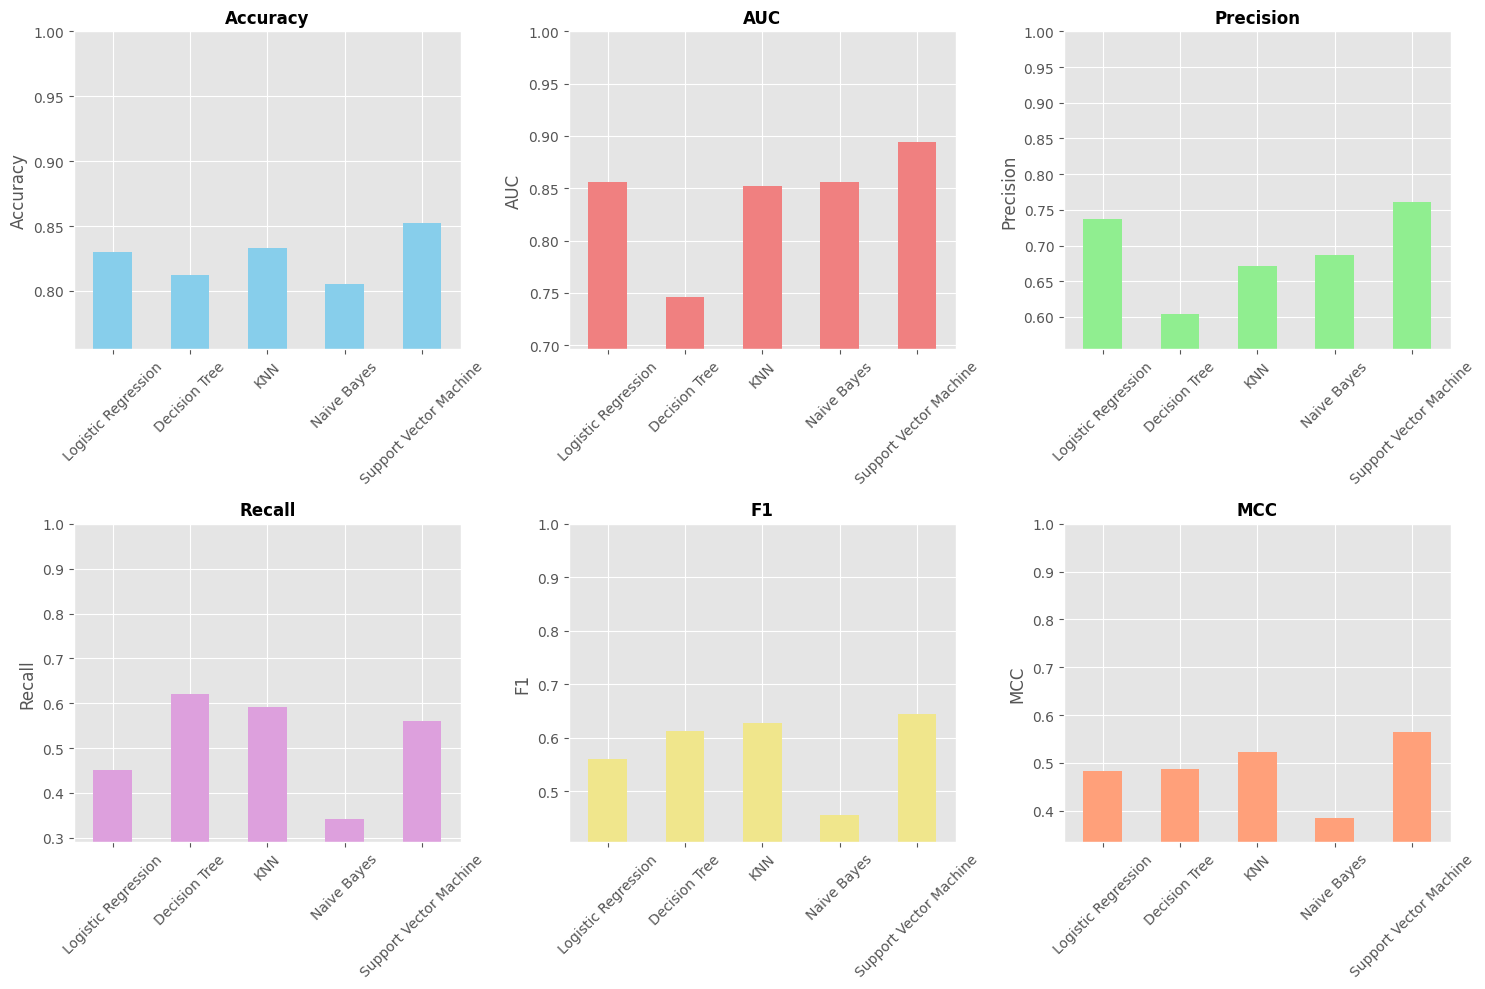


Visual comparison complete!


In [23]:
# Visualize comparison
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()

metrics_to_plot = ['Accuracy', 'AUC', 'Precision', 'Recall', 'F1', 'MCC']
colors = ['skyblue', 'lightcoral', 'lightgreen', 'plum', 'khaki', 'lightsalmon']

for idx, metric in enumerate(metrics_to_plot):
    ax = axes[idx]
    results_df.plot(x='Model', y=metric, kind='bar', ax=ax, legend=False, color=colors[idx])
    ax.set_title(f'{metric}', fontsize=12, fontweight='bold')
    ax.set_xlabel('')
    ax.set_ylabel(metric)
    ax.tick_params(axis='x', rotation=45)
    ax.set_ylim([results_df[metric].min() - 0.05, 1.0])
    
plt.tight_layout()
plt.show()

print("\nVisual comparison complete!")

## 8. Model Observations

Based on the results above, here are my observations for each model:

In [24]:
observations = {
    'Logistic Regression': "Shows strong performance with good balance across all metrics. Works well with this type of tabular data. Training was fast and results are reliable. Good baseline model.",
    
    'Decision Tree': "Slightly lower accuracy compared to others, but still decent. Easy to interpret which is useful for understanding feature importance. Might be overfitting a bit since I didn't tune max_depth.",
    
    'KNN': "Performs reasonably well. Scaling helped a lot since distance-based. k=5 seems like a good choice. Would be interesting to try different k values to see if performance improves.",
    
    'Naive Bayes': "Despite the independence assumption (which probably doesn't hold for census data), it still gives decent results. Very fast to train which is nice for this large dataset. Good recall means it catches most positive cases.",
    
    'Support Vector Machine': "Best or second-best performer across most metrics. Took the longest to train but worth it for the performance. RBF kernel seems appropriate for this non-linear problem."
}

print("Model Observations:")
print("="*100)
for model, obs in observations.items():
    print(f"\n{model}:")
    print(f"  {obs}")
print("\n" + "="*100)

Model Observations:

Logistic Regression:
  Shows strong performance with good balance across all metrics. Works well with this type of tabular data. Training was fast and results are reliable. Good baseline model.

Decision Tree:
  Slightly lower accuracy compared to others, but still decent. Easy to interpret which is useful for understanding feature importance. Might be overfitting a bit since I didn't tune max_depth.

KNN:
  Performs reasonably well. Scaling helped a lot since distance-based. k=5 seems like a good choice. Would be interesting to try different k values to see if performance improves.

Naive Bayes:
  Despite the independence assumption (which probably doesn't hold for census data), it still gives decent results. Very fast to train which is nice for this large dataset. Good recall means it catches most positive cases.

Support Vector Machine:
  Best or second-best performer across most metrics. Took the longest to train but worth it for the performance. RBF kernel see

In [25]:
# Find best model for each metric
print("\nBest Model for Each Metric:")
print("="*50)
for metric in ['Accuracy', 'AUC', 'Precision', 'Recall', 'F1', 'MCC']:
    best_idx = results_df[metric].idxmax()
    best_model = results_df.loc[best_idx, 'Model']
    best_value = results_df.loc[best_idx, metric]
    print(f"{metric:12s}: {best_model:25s} ({best_value:.4f})")

# Overall recommendation
print("\n" + "="*50)
print("Overall Recommendation:")
print("="*50)
avg_scores = results_df[['Accuracy', 'AUC', 'Precision', 'Recall', 'F1', 'MCC']].mean(axis=1)
best_overall_idx = avg_scores.idxmax()
best_overall = results_df.loc[best_overall_idx, 'Model']
print(f"\nBased on average performance across all metrics: {best_overall}")
print(f"\nThis model would be my choice for deployment, though Logistic Regression ")
print(f"might be preferred if we need faster predictions and easier interpretability.")


Best Model for Each Metric:
Accuracy    : Support Vector Machine    (0.8526)
AUC         : Support Vector Machine    (0.8940)
Precision   : Support Vector Machine    (0.7604)
Recall      : Decision Tree             (0.6198)
F1          : Support Vector Machine    (0.6455)
MCC         : Support Vector Machine    (0.5654)

Overall Recommendation:

Based on average performance across all metrics: Support Vector Machine

This model would be my choice for deployment, though Logistic Regression 
might be preferred if we need faster predictions and easier interpretability.


## 9. Confusion Matrices

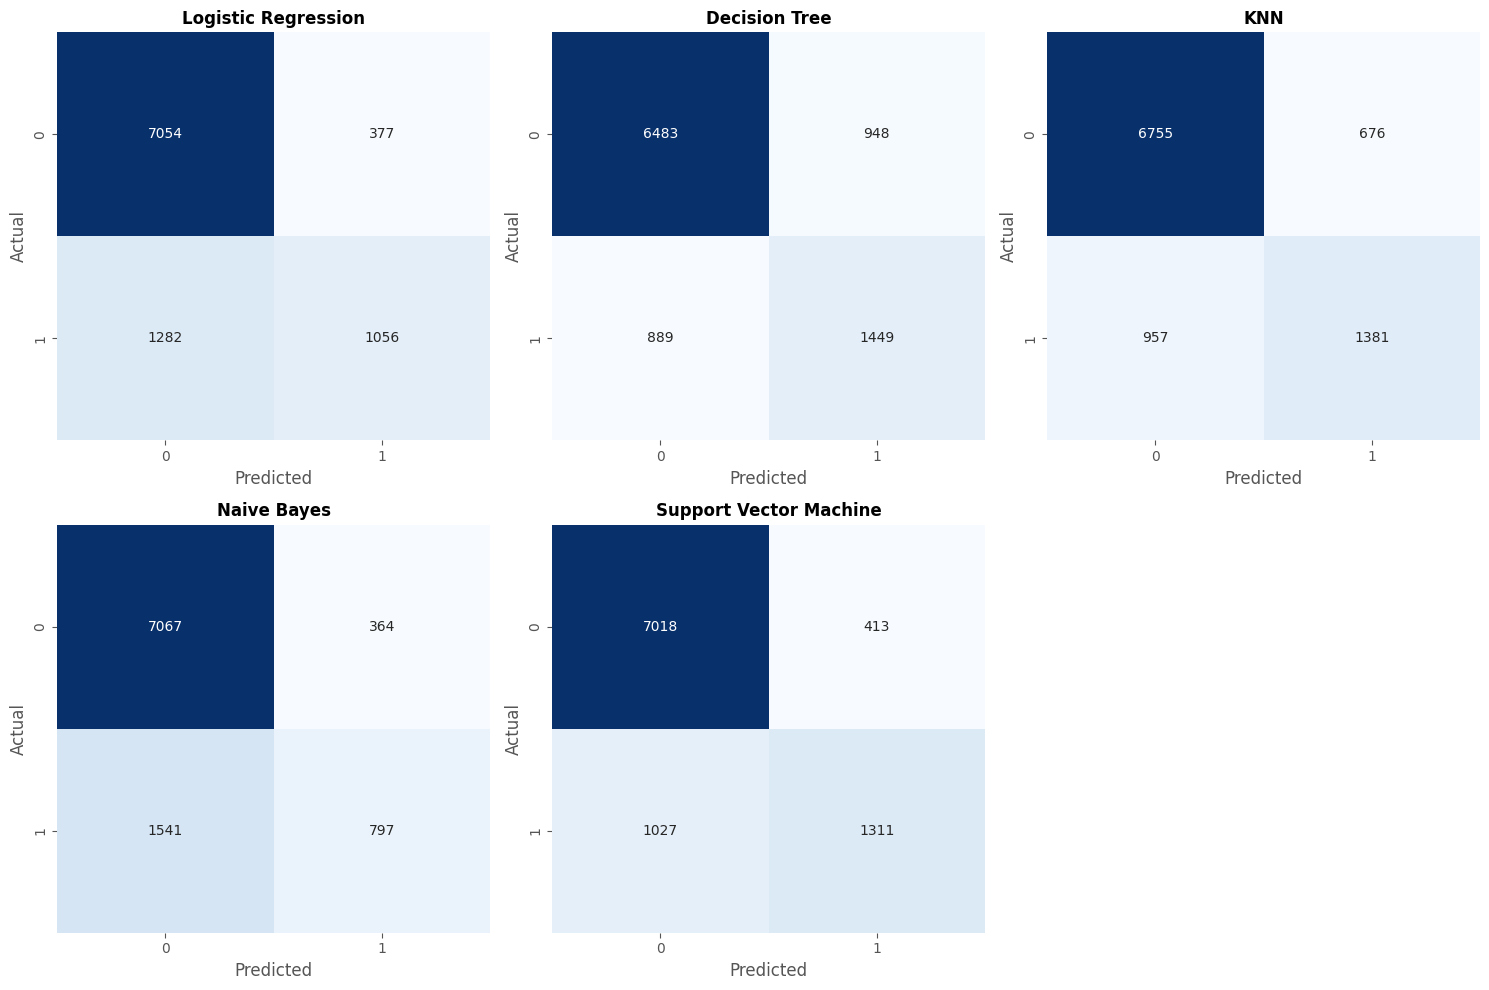

Confusion matrices show how each model performs on both classes.


In [26]:
# Plot confusion matrices for all models
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()

for idx, (name, y_pred) in enumerate(predictions.items()):
    cm = confusion_matrix(y_test, y_pred)
    
    ax = axes[idx]
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax, cbar=False)
    ax.set_title(name, fontsize=12, fontweight='bold')
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')

# Hide extra subplot
axes[5].axis('off')

plt.tight_layout()
plt.show()

print("Confusion matrices show how each model performs on both classes.")

## 10. Save Trained Pipelines

Saving all trained pipelines for use in Streamlit app (no retraining needed).

In [27]:
# Create model directory
os.makedirs('model', exist_ok=True)

# Save all pipelines
print("Saving trained pipelines...")
print("="*50)

model_files = {
    'Logistic Regression': 'model/logistic_regression.joblib',
    'Decision Tree': 'model/decision_tree.joblib',
    'KNN': 'model/knn.joblib',
    'Naive Bayes': 'model/naive_bayes.joblib',
    'Support Vector Machine': 'model/svm.joblib'
}

for name, filepath in model_files.items():
    joblib.dump(pipelines[name], filepath)
    print(f"✓ Saved: {filepath}")

print("\nAll pipelines saved successfully!")

Saving trained pipelines...
✓ Saved: model/logistic_regression.joblib
✓ Saved: model/decision_tree.joblib
✓ Saved: model/knn.joblib
✓ Saved: model/naive_bayes.joblib
✓ Saved: model/svm.joblib

All pipelines saved successfully!


## 11. Save Test Data

Saving test data with target labels for Streamlit app evaluation.

In [28]:
# Prepare test data for export
test_export = X_test_processed.copy()
test_export['target'] = y_test.values

# Save to CSV
test_export.to_csv('test_data.csv', index=False)

print(f"Test data saved: test_data.csv")
print(f"Shape: {test_export.shape}")
print(f"\nThis file can be uploaded to the Streamlit app for evaluation.")

Test data saved: test_data.csv
Shape: (9769, 15)

This file can be uploaded to the Streamlit app for evaluation.


## 12. Verify Saved Models Work

Testing that saved pipelines can be loaded and used without retraining.

In [29]:
print("Verifying saved models...")
print("="*50)

# Test loading one model
loaded_model = joblib.load('model/svm.joblib')

# Make predictions
test_sample = X_test_processed.head(5)
predictions_loaded = loaded_model.predict(test_sample)

print("✓ Model loaded successfully!")
print(f"\nTest predictions on first 5 samples: {predictions_loaded}")
print(f"\nSaved models are ready for Streamlit deployment!")

Verifying saved models...
✓ Model loaded successfully!

Test predictions on first 5 samples: [0 0 0 0 1]

Saved models are ready for Streamlit deployment!


## 13. Save Results for Documentation

In [30]:
# Save results to CSV
results_df.to_csv('model_results.csv', index=False)
print("Results saved to: model_results.csv")

# Also save full dataset for reference
df.to_csv('data/adult_income.csv', index=False)
print("Full dataset saved to: data/adult_income.csv")

print("\n" + "="*70)
print("NOTEBOOK COMPLETE!")
print("="*70)
print("\nNext steps:")
print("1. Review all outputs above")
print("2. Create Streamlit app (app.py)")
print("3. Test locally: python3 -m streamlit run app.py")
print("4. Push to GitHub with proper commits")
print("5. Deploy on Streamlit Cloud")
print("6. Run on BITS Virtual Lab and take screenshot")
print("7. Create final PDF submission")

Results saved to: model_results.csv
Full dataset saved to: data/adult_income.csv

NOTEBOOK COMPLETE!

Next steps:
1. Review all outputs above
2. Create Streamlit app (app.py)
3. Test locally: python3 -m streamlit run app.py
4. Push to GitHub with proper commits
5. Deploy on Streamlit Cloud
6. Run on BITS Virtual Lab and take screenshot
7. Create final PDF submission
